# Demo: segmenting the Falcon Heavy boosters

SAM's automatic mask generator segments the whole image without any prompt. ResNet50 classifies
the image and LayerCAM shows which regions drove that decision. Every SAM mask is scored by how
well it matches the saliency map, overlapping masks are merged into clusters, and the clusters
before the elbow of the score curve form the segmentation.

In [1]:
import matplotlib.pyplot as plt

from saliency_sam import load_image, load_resnet, load_sam, mask_generator, predict, segment, to_tensor
from saliency_sam import plotting
from saliency_sam.models import IMAGENET_LABELS, PROJECT_ROOT
from saliency_sam.xai import LayerCAM, to_image_size

plt.rcParams["figure.dpi"] = 80
image = load_image(PROJECT_ROOT / "assets" / "falcon-heavy-boosters.jpeg")
sam = load_sam("vit_b")
resnet = load_resnet()

## 1. Classify and explain

LayerCAM on ResNet50's last block, scaled to the image and to [0, 1].

In [2]:
img_tensor = to_tensor(image).unsqueeze(0).to(next(resnet.parameters()).device)
class_idx = predict(resnet, img_tensor)
heatmap = to_image_size(LayerCAM(resnet, resnet.layer4)(img_tensor, class_idx), image.shape)
print("ResNet50 prediction:", IMAGENET_LABELS[class_idx])

ResNet50 prediction: missile


## 2. Segment everything, select by saliency

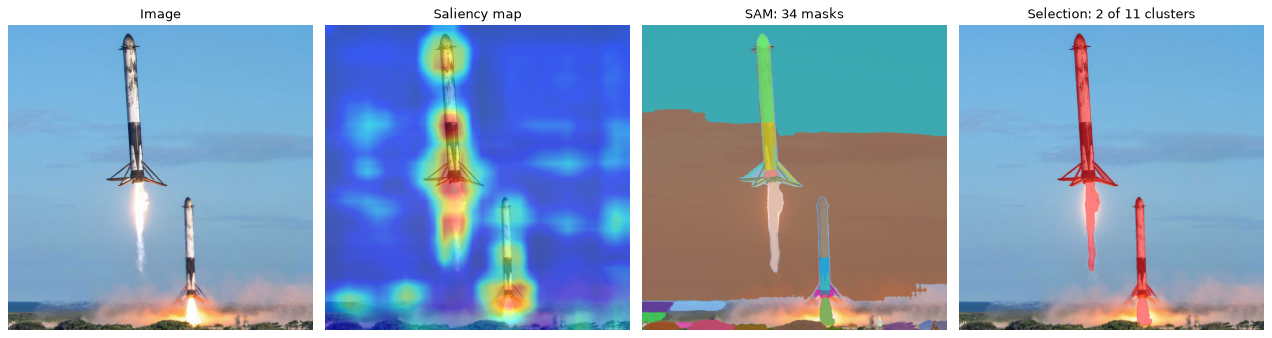

In [3]:
result = segment(image, heatmap, mask_generator(sam))
plotting.overview(image, heatmap, result);

## 3. The steps in detail

**Ranking.** Each mask's score is its soft IoU with the saliency map, multiplied by the mean
relevance inside the mask, so large masks with little relevance (sky, ground) rank low.

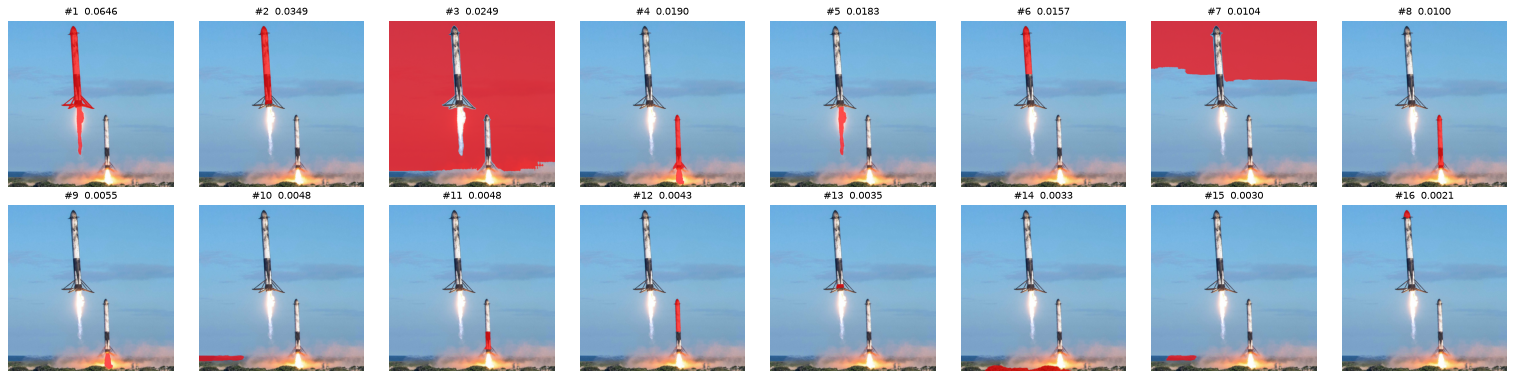

In [4]:
plotting.ranked_masks(image, result, limit=16);

**Clustering.** Going down the ranking, each mask absorbs the later masks it overlaps by more
than 20 %, so parts of one object (booster, legs, engine plume) end up in one cluster. Red
clusters are the selection, gray ones are too large to be selected.

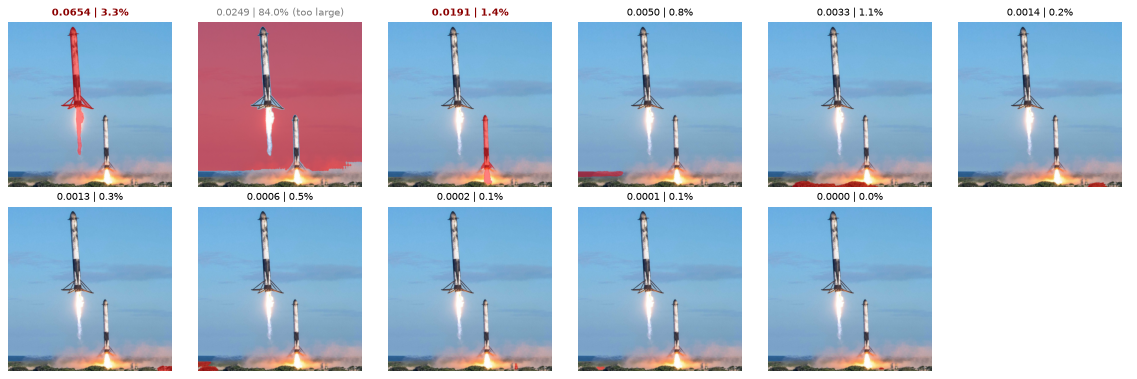

In [5]:
plotting.clusters(image, result);

**Selection.** Clusters covering more than half of the image are background (here the sky)
and left out. The remaining clusters are kept up to the elbow of their score curve: the point
farthest from the line between the best and the worst cluster.

* cluster  1: weighted IoU 0.065368, area  3.31%
- cluster  2: weighted IoU 0.024937, area 83.97%
* cluster  3: weighted IoU 0.019056, area  1.40%
  cluster  4: weighted IoU 0.004976, area  0.84%
  cluster  5: weighted IoU 0.003303, area  1.10%
  cluster  6: weighted IoU 0.001384, area  0.23%
  cluster  7: weighted IoU 0.001343, area  0.26%
  cluster  8: weighted IoU 0.000597, area  0.52%
  cluster  9: weighted IoU 0.000164, area  0.05%
  cluster 10: weighted IoU 0.000135, area  0.08%
  cluster 11: weighted IoU 0.000025, area  0.03%


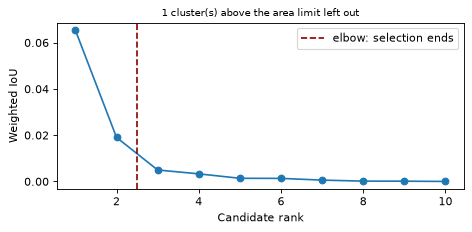

In [6]:
print(plotting.cluster_table(result))
plotting.cluster_scores(result);